<img src="https://github.com/GatorGlaciology/GStatSim/raw/main/images/GatorGlaciologyLogo-01.jpg" width="100" align="right">

# Rubble Glacier bed topography on the GPU 🧊⚡

This notebook runs the whole workflow: radar and rock-outcrop data → gridding →
trend removal → normal-score transform → variogram → **simple kriging** →
**an ensemble of SGS realizations**, using `gstatsim_accel` to run the heavy steps on
an NVIDIA GPU. It also times the GPU against GStatSim and checks that they agree.

It follows GStatSim's *Interpolation with a trend* tutorial. Without a GPU it still
runs, on the CPU (much more slowly).

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import skgstat as skg
from matplotlib.colors import LightSource
from sklearn.preprocessing import QuantileTransformer

import gstatsim as gs
from gstatsim_accel import _batched, gpu_status, kriging, simulation

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "figures"
(FIG / "realizations").mkdir(parents=True, exist_ok=True)
(FIG / "results").mkdir(parents=True, exist_ok=True)

status = gpu_status()
BACKEND = "gpu" if status.available else "cpu"
print("Backend:", BACKEND, "|", status.device_name or status.reason)

C:\Users\alexi\miniforge3\envs\gstatsim-gpu\Lib\site-packages\cupy\_environment.py:286: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


Backend: gpu | NVIDIA GeForce RTX 5060 Laptop GPU


## 1. Data 🛰️

`figures/data/study_area.npz` is cut from BedMachine Antarctica v3 and the Bedmap3
thickness compilation by `figures/prep_map_data.py` (500 m cells, EPSG:3031):

* **Radar bed:** BedMachine surface − Bedmap3 radar ice thickness, on grounded ice.
* **Rock outcrops:** where there's no ice, the bed *is* the surface, which gives exact bed values.
* **BedMachine bed:** kept only to compare against at the end, never used as input.

17,980 radar cells + 6,542 rock-outcrop cells (500 m)


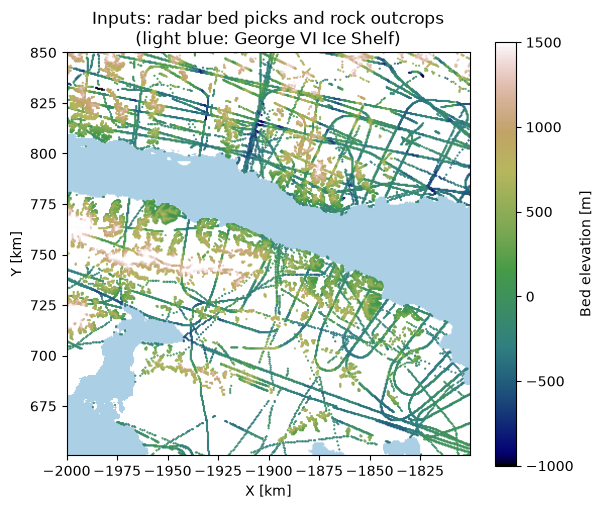

In [2]:
d = np.load(FIG / "data" / "study_area.npz")
radar = pd.DataFrame({"X": d["radar_x"], "Y": d["radar_y"], "Bed": d["radar_bed"]}).astype(float)
rock = pd.DataFrame({"X": d["rock_x"], "Y": d["rock_y"], "Bed": d["rock_bed"]}).astype(float)
data = pd.concat([radar, rock], ignore_index=True)
print(f"{len(radar):,} radar cells + {len(rock):,} rock-outcrop cells (500 m)")

MASK_X, MASK_Y, MASK = d["x"], d["y"], d["mask"]  # BedMachine: 0 ocean, 1 rock, 2 grounded ice, 3 ice shelf
extent = [MASK_X.min() / 1e3, MASK_X.max() / 1e3, MASK_Y.min() / 1e3, MASK_Y.max() / 1e3]

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(np.where(MASK == 3, 1.0, np.nan), extent=extent, cmap="Blues", vmin=0, vmax=3, origin="upper")
im = ax.scatter(data.X / 1e3, data.Y / 1e3, c=data.Bed, s=0.3, cmap="gist_earth", vmin=-1000, vmax=1500)
ax.set(title="Inputs: radar bed picks and rock outcrops\n(light blue: George VI Ice Shelf)",
       xlabel="X [km]", ylabel="Y [km]", aspect="equal")
fig.colorbar(im, ax=ax, label="Bed elevation [m]")
fig.savefig(FIG / "results" / "inputs.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Grid, remove the trend, normal-score transform 📐

The bed rises from about −1,000 m to over 2,000 m across the box, which is not
stationary. As in the GStatSim tutorial, a smooth radial-basis-function trend
(100 km smoothing) is removed and the residuals are kriged and simulated.

In [3]:
RES = 1000  # m
df_grid, grid_matrix, rows, cols = gs.Gridding.grid_data(data, "X", "Y", "Bed", RES)
xmin, xmax, ymin, ymax = df_grid.X.min(), df_grid.X.max(), df_grid.Y.min(), df_grid.Y.max()
df_grid = df_grid[df_grid["Z"].notna()].rename(columns={"Z": "Bed"}).reset_index(drop=True)
pred_xy = gs.Gridding.prediction_grid(xmin, xmax, ymin, ymax, RES)  # row 0 = north
assert len(pred_xy) == rows * cols

t = time.perf_counter()
trend = gs.rbf_trend(grid_matrix, 100_000, RES)  # (rows, cols), row 0 = north
resid = np.flipud(grid_matrix - trend)           # back to grid_data's order (row 0 = south)
df_grid["Residual"] = resid[~np.isnan(resid)]
print(f"{len(df_grid):,} gridded 1 km cells; {rows} x {cols} grid; trend took {time.perf_counter() - t:.0f} s")

nst = QuantileTransformer(n_quantiles=500, output_distribution="normal", random_state=0)
df_grid["NRes"] = nst.fit_transform(df_grid[["Residual"]].to_numpy()).ravel()

# BedMachine mask sampled at the 1 km nodes
ix = np.rint((pred_xy[:, 0] - MASK_X[0]) / 500).astype(int)
iy = np.rint((MASK_Y[0] - pred_xy[:, 1]) / 500).astype(int)
node_mask = MASK[iy, ix]
land = np.isin(node_mask, (1, 2))  # rock + grounded ice: where the data constrain the bed
print(f"{land.sum():,} of {len(pred_xy):,} nodes are rock or grounded ice")

11,010 gridded 1 km cells; 200 x 200 grid; trend took 19 s
30,750 of 40,000 nodes are rock or grounded ice


## 3. Variogram 📈

range 8.1 km, sill 1.028, nugget 0.000


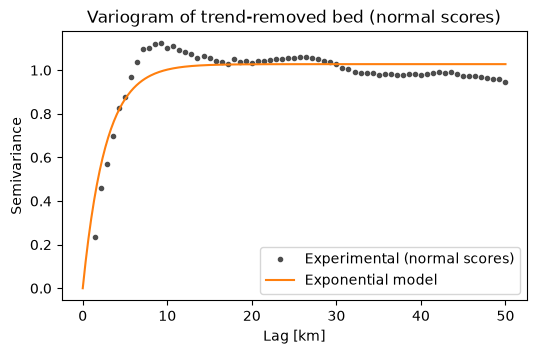

In [4]:
V = skg.Variogram(df_grid[["X", "Y"]].to_numpy(), df_grid["NRes"].to_numpy(),
                  bin_func="even", n_lags=70, maxlag=50_000, normalize=False)
V.model = "exponential"
vrange, sill, nugget = (float(p) for p in V.parameters)
vario = [0.0, nugget, vrange, vrange, sill, "Exponential"]
print(f"range {vrange / 1e3:.1f} km, sill {sill:.3f}, nugget {nugget:.3f}")

h = np.linspace(0, 50_000, 300)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(V.bins / 1e3, V.experimental, "o", ms=3, color="0.3", label="Experimental (normal scores)")
ax.plot(h / 1e3, [skg.models.exponential(x, vrange, sill, nugget) for x in h], color="C1", label="Exponential model")
ax.set(xlabel="Lag [km]", ylabel="Semivariance", title="Variogram of trend-removed bed (normal scores)")
ax.legend()
fig.savefig(FIG / "results" / "variogram.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Simple kriging: GPU vs GStatSim ⏱️

The GPU kriges every node. GStatSim takes about as long per node as before, so
it only gets a random 1,000 nodes here, for timing and for checking agreement.

In [5]:
K, RADIUS = 100, 50_000
kw = dict(num_points=K, radius=RADIUS, zz="NRes")

kriging.predict(df_grid, pred_xy[:200], vario, backend=BACKEND, **kw)  # warm-up (GPU start-up, compilation)
t = time.perf_counter()
est, var = kriging.predict(df_grid, pred_xy, vario, backend=BACKEND, **kw)
t_fast = time.perf_counter() - t

sub = np.random.default_rng(0).choice(len(pred_xy), 1000, replace=False)
t = time.perf_counter()
est_ref, var_ref = kriging.predict(df_grid, pred_xy[sub], vario, backend="cpu", **kw)
t_ref = time.perf_counter() - t

per_node_ref = t_ref / len(sub)
print(f"{BACKEND.upper()}: {t_fast:.2f} s for {len(pred_xy):,} nodes ({1e3 * t_fast / len(pred_xy):.3f} ms/node)")
print(f"GStatSim: {1e3 * per_node_ref:.1f} ms/node -> ~{per_node_ref * len(pred_xy) / 60:.0f} min for the full grid "
      f"(~{per_node_ref * len(pred_xy) / t_fast:.0f}x slower)")
diff = np.abs(est[sub] - est_ref)
print(f"Agreement on the 1,000 nodes: {np.mean(diff <= 1e-6):.1%} within 1e-6; max difference {diff.max():.2e} "
      "(the rest are equidistant-neighbor ties, where GStatSim's choice is arbitrary)")

GPU: 2.34 s for 40,000 nodes (0.058 ms/node)
GStatSim: 3.1 ms/node -> ~2 min for the full grid (~53x slower)
Agreement on the 1,000 nodes: 92.3% within 1e-6; max difference 3.54e-03 (the rest are equidistant-neighbor ties, where GStatSim's choice is arbitrary)


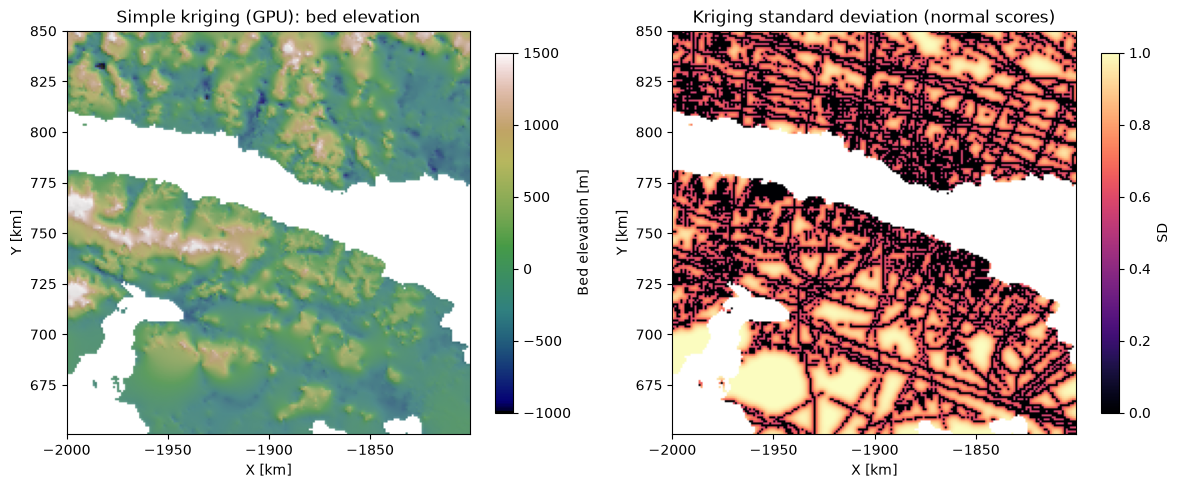

In [6]:
def to_map(values, nodes=None):
    m = np.full(rows * cols, np.nan)
    m[slice(None) if nodes is None else nodes] = values
    return m.reshape(rows, cols)

def bed_map(ax, mat, title, cmap="gist_earth", vmin=-1000, vmax=1500, label="Bed elevation [m]"):
    ls = LightSource(azdeg=45, altdeg=45)
    im = ax.imshow(mat, extent=extent, cmap=cmap, vmin=vmin, vmax=vmax)
    if cmap == "gist_earth":
        shade = ls.hillshade(np.nan_to_num(mat, nan=np.nanmean(mat)), vert_exag=1, dx=RES, dy=RES)
        ax.imshow(np.where(np.isnan(mat), np.nan, shade), extent=extent, cmap="gray", alpha=0.25)
    ax.set(title=title, xlabel="X [km]", ylabel="Y [km]")
    ax.locator_params(axis="x", nbins=5)
    plt.colorbar(im, ax=ax, label=label, shrink=0.8)

sk_bed = nst.inverse_transform(est.reshape(-1, 1)).reshape(rows, cols) + trend
sk_bed[~land.reshape(rows, cols)] = np.nan
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
bed_map(axs[0], sk_bed, "Simple kriging (GPU): bed elevation")
bed_map(axs[1], to_map(np.sqrt(np.clip(var, 0, None))).reshape(rows, cols) * np.where(land.reshape(rows, cols), 1, np.nan),
        "Kriging standard deviation (normal scores)", cmap="magma", vmin=0, vmax=1, label="SD")
fig.tight_layout()
fig.savefig(FIG / "results" / "kriging.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. SGS ensemble 🎲

Each realization is a different, equally likely bed that honors the data and the
variogram, so the spread across realizations is the uncertainty. SGS is sequential,
but separate realizations are independent, so the GPU steps all of them forward
together. Each realization is the same one GStatSim produces with that seed.

In [7]:
N_REAL = 20
sim_nodes = np.flatnonzero(land)
t = time.perf_counter()
sims = simulation.realizations(df_grid, pred_xy[sim_nodes], vario, seeds=list(range(N_REAL)),
                               backend=BACKEND, **kw)
t_sgs = time.perf_counter() - t
print(f"{N_REAL} realizations x {len(sim_nodes):,} nodes on {BACKEND.upper()}: {t_sgs / 60:.1f} min "
      f"({t_sgs / N_REAL:.0f} s per realization)")

beds = nst.inverse_transform(sims.reshape(-1, 1)).reshape(sims.shape) + trend.ravel()[sim_nodes]
real_maps = np.stack([to_map(b, sim_nodes) for b in beds])

20 realizations x 30,750 nodes on GPU: 4.0 min (12 s per realization)


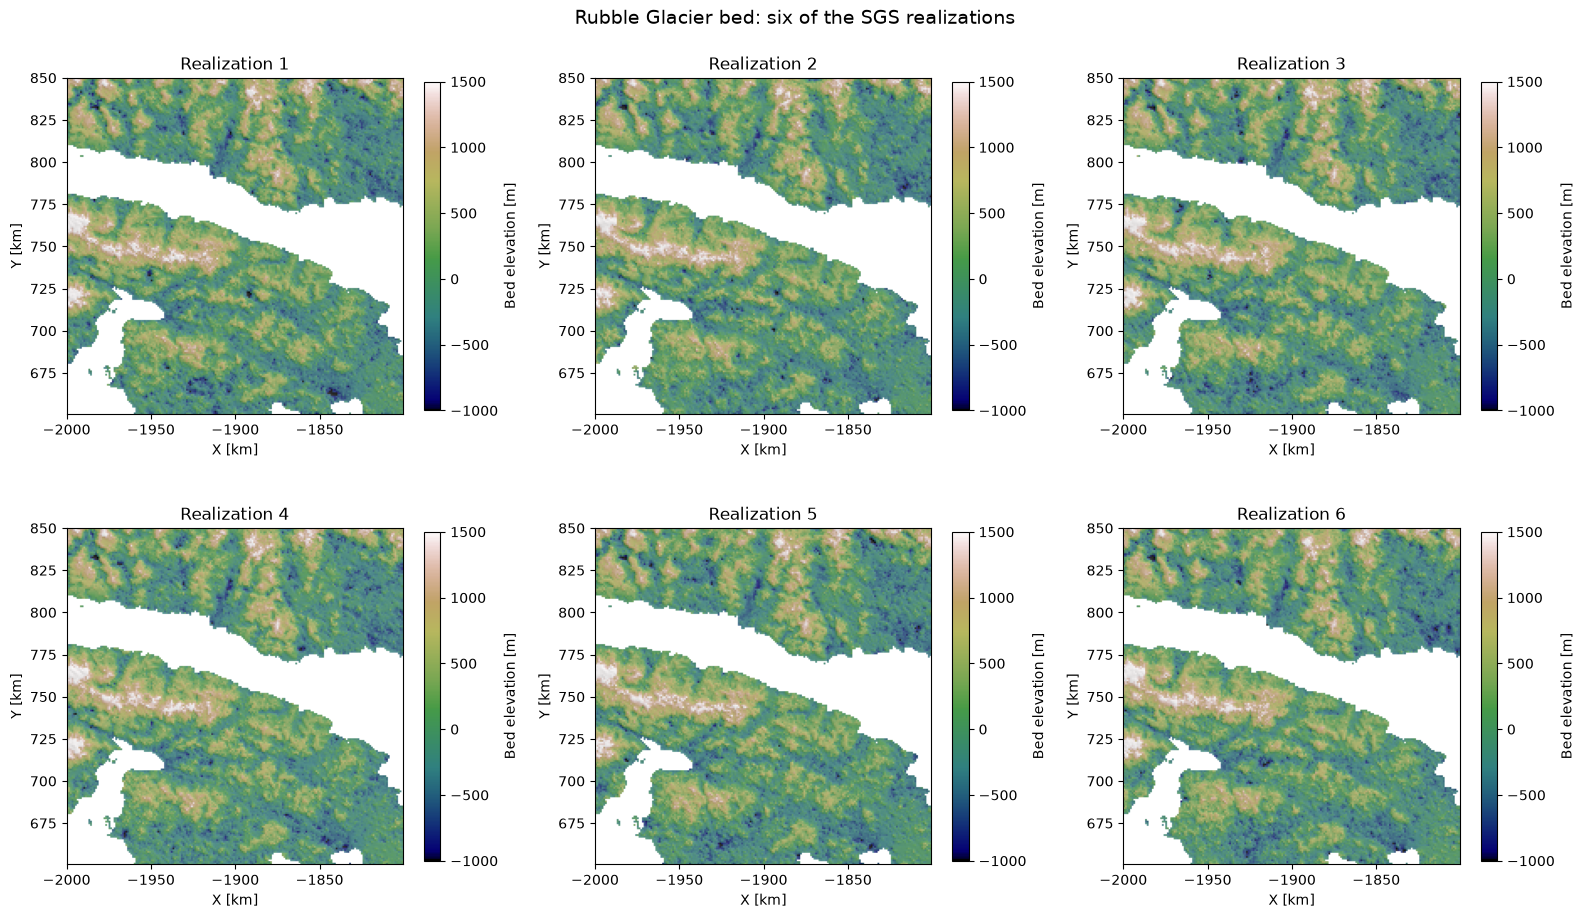

In [8]:
for i in range(6):
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    bed_map(ax, real_maps[i], f"SGS realization {i + 1} (seed {i})")
    fig.savefig(FIG / "realizations" / f"realization_{i + 1:02d}.png", dpi=150, bbox_inches="tight")
    plt.close(fig)

fig, axs = plt.subplots(2, 3, figsize=(16, 9.5))
for i, ax in enumerate(axs.flat):
    bed_map(ax, real_maps[i], f"Realization {i + 1}")
fig.suptitle("Rubble Glacier bed: six of the SGS realizations", fontsize=14)
fig.tight_layout()
fig.savefig(FIG / "realizations" / "realizations_panel.png", dpi=130, bbox_inches="tight")
plt.show()

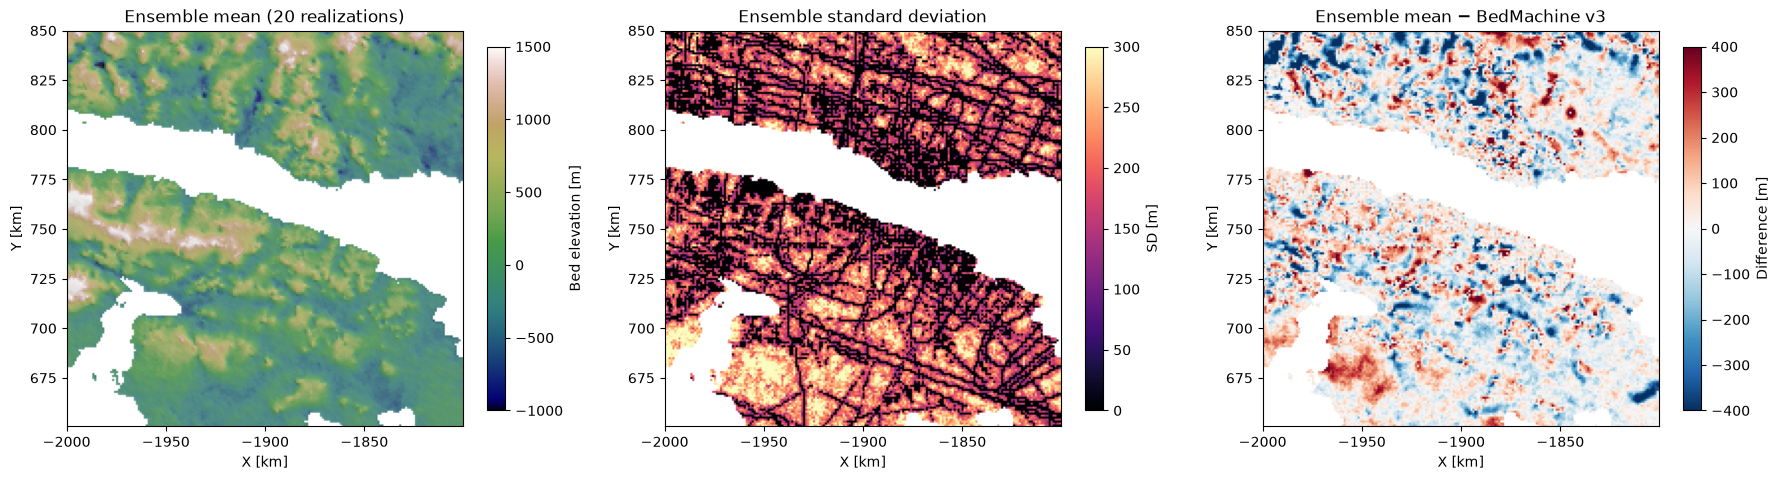

Mean |ensemble mean − BedMachine| on land: 110 m


In [9]:
mean_map, sd_map = to_map(beds.mean(axis=0), sim_nodes), to_map(beds.std(axis=0), sim_nodes)
bm = d["bedmachine_bed"][iy, ix].reshape(rows, cols).astype(float)
bm[~land.reshape(rows, cols)] = np.nan

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
bed_map(axs[0], mean_map, f"Ensemble mean ({N_REAL} realizations)")
bed_map(axs[1], sd_map, "Ensemble standard deviation", cmap="magma", vmin=0, vmax=300, label="SD [m]")
bed_map(axs[2], mean_map - bm, "Ensemble mean − BedMachine v3", cmap="RdBu_r", vmin=-400, vmax=400,
        label="Difference [m]")
fig.tight_layout()
fig.savefig(FIG / "realizations" / "ensemble_mean_sd.png", dpi=130, bbox_inches="tight")
plt.show()
print(f"Mean |ensemble mean − BedMachine| on land: {np.nanmean(np.abs(mean_map - bm)):.0f} m")

## 6. Do the realizations honor the data? ✅

Realizations should reproduce the data's histogram and variogram (in normal-score
units: mean ≈ 0, variance ≈ 1, same variogram shape).

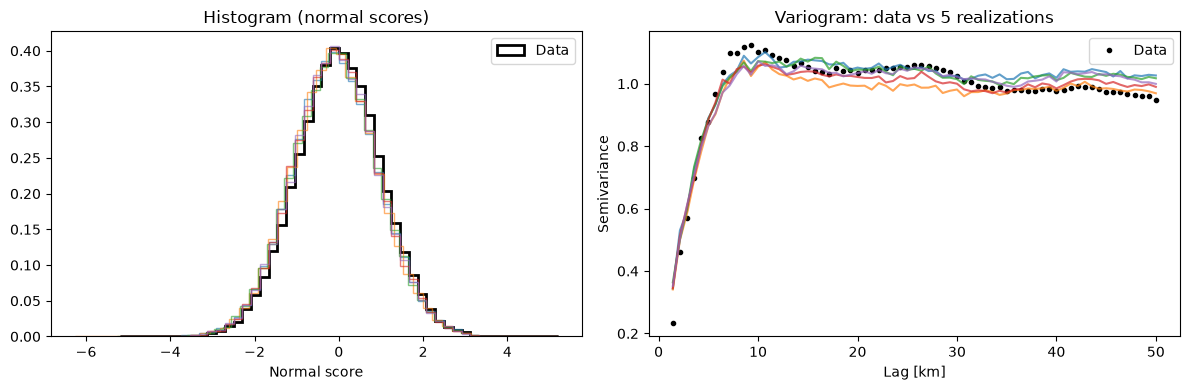

Realization mean/variance (normal scores): -0.07/1.05, -0.09/1.02, -0.10/1.04, -0.07/1.02, -0.08/1.02


In [10]:
rng = np.random.default_rng(1)
pick = rng.choice(len(sim_nodes), min(5000, len(sim_nodes)), replace=False)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].hist(df_grid["NRes"], bins=50, density=True, histtype="step", lw=2, color="k", label="Data")
for i in range(5):
    axs[0].hist(sims[i], bins=50, density=True, histtype="step", alpha=0.6)
axs[0].set(title="Histogram (normal scores)", xlabel="Normal score")
axs[0].legend()
axs[1].plot(V.bins / 1e3, V.experimental, "ko", ms=3, label="Data")
for i in range(5):
    Vs = skg.Variogram(pred_xy[sim_nodes][pick], sims[i][pick], bin_func="even", n_lags=70,
                       maxlag=50_000, normalize=False)
    axs[1].plot(Vs.bins / 1e3, Vs.experimental, alpha=0.7)
axs[1].set(title="Variogram: data vs 5 realizations", xlabel="Lag [km]", ylabel="Semivariance")
axs[1].legend()
fig.tight_layout()
fig.savefig(FIG / "results" / "realization_checks.png", dpi=150, bbox_inches="tight")
plt.show()
print("Realization mean/variance (normal scores):",
      ", ".join(f"{s.mean():.2f}/{s.var():.2f}" for s in sims[:5]))

## 7. Summary ⏱️

Times measured in this run. GStatSim's full-grid times are estimated from its
measured time per node; its SGS estimate is a lower bound, since GStatSim's SGS
also copies a growing table at every step.

In [11]:
sgs_ref = per_node_ref * len(sim_nodes)
summary = pd.DataFrame({
    "GStatSim (CPU)": [f"~{per_node_ref * len(pred_xy) / 60:.0f} min (est.)", f">= {sgs_ref / 60:.0f} min (est.)"],
    f"This project ({BACKEND.upper()})": [f"{t_fast:.1f} s", f"{t_sgs / N_REAL:.0f} s ({N_REAL} together)"],
    "Speedup": [f"~{per_node_ref * len(pred_xy) / t_fast:.0f}x", f">= {sgs_ref / (t_sgs / N_REAL):.0f}x"],
}, index=[f"Simple kriging, {len(pred_xy):,} nodes", f"SGS, per realization, {len(sim_nodes):,} nodes"])
summary

,GStatSim (CPU),This project (GPU),Speedup
"Simple kriging, 40,000 nodes",~2 min (est.),2.3 s,~53x
"SGS, per realization, 30,750 nodes",>= 2 min (est.),12 s (20 together),>= 8x


The GPU results match GStatSim to ~1e-12 wherever the choice of neighbors is
unambiguous; the tests in `tests/` and the checks in `benchmarks/` cover the details.